# 👻  **Taller Dask - Brecha digital en Colombia 🛰️**

<img src="https://www.udistrital.edu.co/themes/custom/versh/images/default/preloader.png" align="left" width="192px" height="192px"/>
<img align="left" width="0" height="192px" hspace="10"/>

> Juan Felipe Rodríguez Galindo  - **COD. 20261595004**
<br></br>
[![Juan Felipe Rodriguez Galindo](https://img.shields.io/badge/Juferoga-github-br?style=flat-square)](https://github.com/Juferoga)
[![License](https://img.shields.io/badge/License-GPL_V.3-blue?style=flat-square)](https://www.gnu.org/licenses/gpl-3.0.html)


Computación paralela — Módulo 8: Computación paralela/distribuida para ciencia de datos e IA (Dask)

Desarrollo del taller de Dask propuesto en la clase de Computación Paralela.

## Enunciado

Leer uno o varios datasets de **Datos Abiertos Colombia** y crear un Colab donde se utilicen esos datos y como mínimo las siguientes operaciones:

1. Estadística descriptiva
2. Filtros
3. Map o Apply
4. Joins
5. Visualización
6. Paralelización con todos los modos vistos

## Pregunta que guía el análisis

> **¿Qué tan grande es la brecha digital entre Bogotá y el resto de Colombia, y cómo ha cambiado desde que llegó la fibra óptica?**

Para responderla se usan los reportes que los proveedores de internet fijo entregan trimestralmente a MinTIC (cada fila es una combinación *proveedor × municipio × segmento × tecnología × velocidad* con su número de accesos), y se cruzan con la población DANE y las coordenadas DIVIPOLA de cada municipio.

MinTIC publica estos reportes en **dos datasets**: el histórico (hasta 2023-T3) y el actual (desde 2023-T4, con otros nombres de columna). Se concatenan con Dask para tener una sola serie de ~4,9 millones de registros.

| # | Dataset (datos.gov.co) | ID | Filas aprox. | Uso |
|---|---|---|---|---|
| 1 | [Internet Fijo Accesos por tecnología y segmento](https://www.datos.gov.co/d/n48w-gutb) — MinTIC (2016 a 2023-T3) | `n48w-gutb` | ~2,8 M | Tabla principal, parte histórica |
| 2 | [Accesos Fijos a Internet por Proveedor, Departamento, Municipio, Tecnología, Segmento y ancho de banda](https://www.datos.gov.co/d/hwrp-3su3) — MinTIC (2023-T4 en adelante) | `hwrp-3su3` | ~2,1 M | Tabla principal, parte reciente |
| 3 | [Accesos Fijos a Internet por Departamento, Municipio y población](https://www.datos.gov.co/d/tvzi-ba2g) — MinTIC | `tvzi-ba2g` | ~12 k | Join: población DANE por municipio/trimestre |
| 4 | [DIVIPOLA - Códigos municipios](https://www.datos.gov.co/d/gdxc-w37w) — DANE | `gdxc-w37w` | ~1,1 k | Join: latitud/longitud para el mapa |

> **Entorno:** funciona en Google Colab con el runtime por defecto (CPU). No requiere GPU.

# 1. Verificación del entorno

In [1]:
# Sistema operativo y recursos disponibles (en Colab normalmente 2 núcleos y ~12 GB de RAM)
!uname -a
!nproc 2>/dev/null || sysctl -n hw.ncpu
!free -h 2>/dev/null || true

Darwin MacBook-Air-de-juferoga.local 27.2.0 Darwin Kernel Version 27.2.0: Wed Oct 14 23:46:57 PDT 2026; root:xnu-13432.41.4~25/RELEASE_ARM64_T8103 arm64


8


In [2]:
# Dask "complete" trae dask.dataframe, dask.array, dask.bag, dask.delayed y dask.distributed.
# graphviz se usa para dibujar el grafo de tareas.
%pip install -q "dask[complete]" graphviz


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: /private/tmp/claude-501/-Users-juferoga-repos-ud-maestria-mcic-semestre-2-mcic-parallel-computing/23331993-f865-4202-bbc6-64aa4734c271/scratchpad/venv/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
import csv
import time
import glob
import math
import operator
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

import dask
import dask.dataframe as dd
import dask.bag as db
import dask.array as da
from dask.diagnostics import ProgressBar
import distributed
from dask.distributed import Client, LocalCluster, as_completed

warnings.filterwarnings("ignore")
import logging
logging.getLogger("distributed").setLevel(logging.ERROR)   # menos ruido en la salida del clúster
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams.update({"figure.figsize": (11, 5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

NUCLEOS = os.cpu_count() or 2
print(f"dask {dask.__version__} | distributed {distributed.__version__} | pandas {pd.__version__} | numpy {np.__version__}")
print(f"Núcleos disponibles: {NUCLEOS}")

dask 2026.8.0 | distributed 2026.8.0 | pandas 3.1.1 | numpy 2.5.5
Núcleos disponibles: 8


# 2. Obtención de los datos (Datos Abiertos Colombia)

Los datasets se descargan con la API SODA de `datos.gov.co`. Entre los dos datasets de accesos hay casi 5 millones de filas, así que se bajan **por páginas de 250.000 registros**, y las páginas se piden **en paralelo con `dask.delayed`**: es trabajo de red (I/O), así que conviene el scheduler de **hilos**. Este es el primer uso de paralelismo del taller.

Cada página queda guardada como un CSV (`datos/<carpeta>/parte_XX.csv`). Después Dask lee cada archivo como una **partición**. Si los archivos ya existen no se vuelven a descargar.

In [4]:
DATOS = "datos"
BASE = "https://www.datos.gov.co/resource"
FUENTES = {"accesos": "n48w-gutb",              # histórico 2016 - 2023-T3
           "accesos_recientes": "hwrp-3su3"}    # 2023-T4 en adelante
ID_POBLACION, ID_DIVIPOLA = "tvzi-ba2g", "gdxc-w37w"
TAM_PAGINA = 250_000
for carpeta in FUENTES:
    os.makedirs(f"{DATOS}/{carpeta}", exist_ok=True)


def contar_filas(id_dataset):
    # SoQL: SELECT count(*) -> número total de registros del dataset
    r = requests.get(f"{BASE}/{id_dataset}.json", params={"$select": "count(*)"}, timeout=60)
    r.raise_for_status()
    return int(r.json()[0]["count"])


@dask.delayed
def descargar_pagina(carpeta, id_dataset, i):
    # Descarga la página i de un dataset. Es una tarea perezosa (delayed):
    # no se ejecuta hasta llamar a dask.compute.
    ruta = f"{DATOS}/{carpeta}/parte_{i:02d}.csv"
    if os.path.exists(ruta) and os.path.getsize(ruta) > 0:
        return ruta                                  # ya estaba descargada
    params = {"$limit": TAM_PAGINA, "$offset": i * TAM_PAGINA, "$order": ":id"}  # orden estable
    with requests.get(f"{BASE}/{id_dataset}.csv", params=params, stream=True, timeout=900) as r:
        r.raise_for_status()
        with open(ruta + ".tmp", "wb") as f:
            for bloque in r.iter_content(chunk_size=1 << 20):
                f.write(bloque)
    os.replace(ruta + ".tmp", ruta)                  # escritura atómica: no deja archivos a medias
    return ruta


def descargar_simple(id_dataset, ruta, limite=100_000):
    # Los datasets pequeños se bajan en una sola petición
    if not os.path.exists(ruta):
        r = requests.get(f"{BASE}/{id_dataset}.csv", params={"$limit": limite}, timeout=300)
        r.raise_for_status()
        open(ruta, "wb").write(r.content)
    return ruta


tareas = []                                     # grafo de tareas (aún no corre nada)
for carpeta, id_dataset in FUENTES.items():
    total = contar_filas(id_dataset)
    n_paginas = math.ceil(total / TAM_PAGINA)
    print(f"{id_dataset}: {total:,} registros -> {n_paginas} páginas de {TAM_PAGINA:,}")
    tareas += [descargar_pagina(carpeta, id_dataset, i) for i in range(n_paginas)]

t0 = time.perf_counter()
with ProgressBar():
    rutas = dask.compute(*tareas, scheduler="threads", num_workers=6)  # descargas simultáneas
descargar_simple(ID_POBLACION, f"{DATOS}/poblacion.csv")
descargar_simple(ID_DIVIPOLA, f"{DATOS}/divipola.csv")
print(f"{len(rutas)} páginas listas. Descarga terminada en {time.perf_counter() - t0:,.1f} s")
!du -sh {DATOS}/* && ls {DATOS}

n48w-gutb: 2,795,052 registros -> 12 páginas de 250,000


hwrp-3su3: 2,072,381 registros -> 9 páginas de 250,000
[                                        ] | 0% Completed | 177.42 us

[########################################] | 100% Completed | 107.00 ms

21 páginas listas. Descarga terminada en 0.1 s


390M	datos/accesos
295M	datos/accesos_recientes
 84K	datos/divipola.csv
992K	datos/poblacion.csv
accesos           accesos_recientes divipola.csv      poblacion.csv


# 3. Lectura con Dask DataFrame

`dd.read_csv` **no lee nada todavía**: construye un plan perezoso con una partición por archivo (`blocksize=None`). Cada partición es un `pandas.DataFrame` que se procesa en paralelo cuando se pide un resultado (`.compute()`, `len()`, `.head()`).

Pasos de preparación:
- Los dos datasets tienen **columnas con nombres distintos** (`cod_municipio` vs `codigo_dane_municipio`, `no_de_accesos` vs `accesos_fijos_internet`): se renombran y se unen con `dd.concat`.
- El dataset reciente trae los códigos DANE **sin cero inicial** (`5001` en vez de `05001`): se rellenan con `zfill`.
- Las velocidades vienen con **coma decimal** en el histórico (`"8,00"`) y con punto en el reciente: se pasan a `float`.
- Hay registros con velocidades imposibles para un acceso fijo (hasta millones de Mbps): por encima de **10.000 Mbps (10 Gbps)** se consideran error de reporte y la velocidad queda como `NaN` (los accesos se conservan para los conteos).
- Los trimestres anteriores a **2017-T2** tienen el reporte incompleto (pocas decenas de registros), así que se descartan.
- Se construyen `periodo` (`2024-T3`), `acc_x_vel` (velocidad × accesos) y `acc_con_vel` (accesos con velocidad válida), que sirven para los promedios ponderados.

In [5]:
# Todo se lee como texto y luego se convierte de forma explícita (evita errores de inferencia de tipos entre particiones)
historico = dd.read_csv(f"{DATOS}/accesos/parte_*.csv", dtype=str, blocksize=None)
reciente = dd.read_csv(f"{DATOS}/accesos_recientes/parte_*.csv", dtype=str, blocksize=None)
print("Columnas histórico:", list(historico.columns))
print("Columnas reciente: ", list(reciente.columns))
COLUMNAS_RECIENTE = list(reciente.columns)       # se guardan los nombres originales (se usan en dask.bag)

reciente = reciente.rename(columns={"codigo_dane_departamento": "cod_departamento",
                                    "codigo_dane_municipio": "cod_municipio",
                                    "accesos_fijos_internet": "no_de_accesos"})
df_crudo = dd.concat([historico, reciente[list(historico.columns)]])   # mismo orden de columnas
# El dataset reciente quita el cero inicial de los códigos DANE ("5001" en vez de "05001"): se rellenan
df_crudo["cod_departamento"] = df_crudo["cod_departamento"].str.zfill(2)
df_crudo["cod_municipio"] = df_crudo["cod_municipio"].str.zfill(5)

VEL_MAX = 10_000          # Mbps; por encima se considera error de reporte


def a_numero(serie):
    # "150,00" -> 150.0  |  "2.5" -> 2.5
    return serie.str.replace(",", ".", regex=False).astype("float64")


df_tipado = df_crudo.assign(
    anno=df_crudo["anno"].astype("int32"),
    trimestre=df_crudo["trimestre"].astype("int8"),
    velocidad_bajada=a_numero(df_crudo["velocidad_bajada"]),
    velocidad_subida=a_numero(df_crudo["velocidad_subida"]),
    no_de_accesos=df_crudo["no_de_accesos"].astype("int64"),
)
df_tipado["periodo"] = df_tipado["anno"].astype(str) + "-T" + df_tipado["trimestre"].astype(str)
invalida = (df_tipado["velocidad_bajada"] > VEL_MAX) | (df_tipado["velocidad_subida"] > VEL_MAX)

df_lazy = df_tipado.assign(
    velocidad_bajada=df_tipado["velocidad_bajada"].mask(invalida),
    velocidad_subida=df_tipado["velocidad_subida"].mask(invalida),
)
df_lazy["acc_con_vel"] = df_lazy["no_de_accesos"].where(~invalida, 0)
df_lazy["acc_x_vel"] = (df_lazy["velocidad_bajada"] * df_lazy["no_de_accesos"]).fillna(0)
df_lazy = df_lazy[df_lazy["periodo"] >= "2017-T2"]                   # trimestres con reporte completo

print("\nParticiones:", df_lazy.npartitions, f"({historico.npartitions} histórico + {reciente.npartitions} reciente)")
print(df_lazy.dtypes)
df_lazy  # solo muestra la estructura: aún no hay datos en memoria

Columnas histórico: ['anno', 'trimestre', 'proveedor', 'cod_departamento', 'departamento', 'cod_municipio', 'municipio', 'segmento', 'tecnologia', 'velocidad_bajada', 'velocidad_subida', 'no_de_accesos']
Columnas reciente:  ['anno', 'trimestre', 'proveedor', 'codigo_dane_departamento', 'departamento', 'codigo_dane_municipio', 'municipio', 'segmento', 'tecnologia', 'velocidad_bajada', 'velocidad_subida', 'accesos_fijos_internet']

Particiones: 21 (12 histórico + 9 reciente)
anno                  int32
trimestre              int8
proveedor            string
cod_departamento     string
departamento         string
cod_municipio        string
municipio            string
segmento             string
tecnologia           string
velocidad_bajada    float64
velocidad_subida    float64
no_de_accesos         int64
periodo                 str
acc_con_vel           int64
acc_x_vel           float64
dtype: object


,anno,trimestre,proveedor,cod_departamento,departamento,cod_municipio,municipio,segmento,tecnologia,velocidad_bajada,velocidad_subida,no_de_accesos,periodo,acc_con_vel,acc_x_vel
npartitions=21,,,,,,,,,,,,,,,
,int32,int8,string,string,string,string,string,string,string,float64,float64,int64,str,int64,float64
,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...


In [6]:
# .head() solo lee la primera partición
df_lazy.head()

,anno,trimestre,proveedor,cod_departamento,departamento,cod_municipio,municipio,segmento,tecnologia,velocidad_bajada,velocidad_subida,no_de_accesos,periodo,acc_con_vel,acc_x_vel
0,2023,2,DIRECTV COLOMBIA LTDA,08,ATLÁNTICO,08520,PALMAR DE VARELA,RESIDENCIAL - ESTRATO 1,OTRAS TECNOLOGÍAS INALÁMBRICAS,6.00,1.00,3,2023-T2,3,18.00
1,2021,2,COCOM S.A.S,63,QUINDÍO,63272,FILANDIA,RESIDENCIAL - ESTRATO 2,WIFI,5.00,5.00,1,2021-T2,1,5.00
2,2021,1,COMUNICACION CELULAR S A COMCEL S A,08,ATLÁNTICO,08001,BARRANQUILLA,RESIDENCIAL - ESTRATO 2,CABLE,10.00,5.00,43,2021-T1,43,430.00
3,2021,3,COLOMBIA TELECOMUNICACIONES S.A. E.S.P.,76,VALLE DEL CAUCA,76001,CALI,RESIDENCIAL - ESTRATO 5,OTRAS TECNOLOGÍAS DE FIBRA (ANTES FTTX),15.00,1.00,16,2021-T3,16,240.00
4,2023,3,DIFUDATOS S A S,25,CUNDINAMARCA,25224,CUCUNUBÁ,CORPORATIVO,OTRAS TECNOLOGÍAS INALÁMBRICAS,30.00,24.00,1,2023-T3,1,30.00


In [7]:
# len() sí recorre todas las particiones (lectura + conversión en paralelo).
with ProgressBar():
    t0 = time.perf_counter()
    n_crudo, n_filas, n_invalidas, acc_invalidos = dask.compute(
        len(df_crudo), len(df_lazy), invalida.sum(), df_tipado["no_de_accesos"][invalida].sum())
    t_lectura = time.perf_counter() - t0
print(f"Filas crudas: {n_crudo:,} | tras filtrar periodos incompletos: {n_filas:,}")
print(f"Registros con velocidad > {VEL_MAX:,} Mbps (marcados NaN): {n_invalidas:,} ({acc_invalidos:,} accesos)")
print(f"Tiempo leyendo y limpiando desde CSV: {t_lectura:,.1f} s")

# Cada .compute() sobre df_lazy vuelve a leer los CSV. Para el análisis exploratorio se usa
# .persist(): ejecuta el plan una vez y deja las particiones en memoria (siguen siendo un Dask DataFrame).
with ProgressBar():
    df = df_lazy.persist()

t0 = time.perf_counter()
len(df)
print(f"len() con los datos persistidos: {time.perf_counter() - t0:,.2f} s")
print(f"Memoria aproximada: {df.memory_usage(deep=True).sum().compute() / 1e9:,.2f} GB")

[                                        ] | 0% Completed | 76.12 us

[                                        ] | 0% Completed | 128.78 ms

[                                        ] | 0% Completed | 342.80 ms

[                                        ] | 0% Completed | 462.38 ms

[                                        ] | 0% Completed | 614.09 ms

[                                        ] | 0% Completed | 798.96 ms

... (116 outputs left out)

[####################################    ] | 92% Completed | 4.36 s

[######################################  ] | 96% Completed | 4.49 s

[########################################] | 100% Completed | 4.60 s

len() con los datos persistidos: 0.00 s
Memoria aproximada: 1.04 GB


# 4. Estadística descriptiva

Ojo con un detalle del dataset: **cada fila no es un acceso**, es un grupo de accesos con la misma velocidad. Por eso los promedios "reales" de velocidad se calculan **ponderados por `no_de_accesos`**:

$$\bar v = \frac{\sum_i v_i \cdot n_i}{\sum_i n_i} = \frac{\texttt{sum(acc\_x\_vel)}}{\texttt{sum(acc\_con\_vel)}}$$

`dask.compute(a, b, c, ...)` ejecuta varias agregaciones en **una sola pasada** sobre los datos, compartiendo las tareas comunes del grafo.

In [8]:
# Resumen clásico (count, mean, std, min, percentiles aproximados, max) por fila
df[["velocidad_bajada", "velocidad_subida", "no_de_accesos"]].describe().compute()

,velocidad_bajada,velocidad_subida,no_de_accesos
count,"4,852,585.00","4,852,585.00","4,861,507.00"
mean,135.25,86.35,62.81
std,375.53,327.47,848.72
min,0.00,0.00,0.00
25%,16.00,5.00,1.00
50%,80.00,25.00,3.00
75%,350.00,200.00,19.00
max,"10,000.00","10,000.00","235,431.00"


In [9]:
vel_pond = df["acc_x_vel"].sum() / df["acc_con_vel"].sum()
sub_pond = (df["velocidad_subida"] * df["no_de_accesos"]).sum() / df["acc_con_vel"].sum()

(periodos, n_prov, n_mun, n_dep, vel_pond, sub_pond, cuantiles, mediana_acc) = dask.compute(
    df["periodo"].unique(),
    df["proveedor"].nunique(),
    df["cod_municipio"].nunique(),
    df["cod_departamento"].nunique(),
    vel_pond,
    sub_pond,
    df["velocidad_bajada"].quantile([0.10, 0.25, 0.50, 0.75, 0.90, 0.99]),
    df["no_de_accesos"].median_approximate(),
)
periodos = sorted(periodos)
print(f"Periodos: {periodos[0]} a {periodos[-1]} ({len(periodos)} trimestres)")
print(f"Proveedores distintos: {n_prov:,} | Municipios: {n_mun:,} | Departamentos: {n_dep}")
print(f"Velocidad de bajada ponderada (todos los periodos): {vel_pond:,.1f} Mbps | subida: {sub_pond:,.1f} Mbps")
print(f"Mediana de accesos por registro: {mediana_acc}")
print("\nCuantiles de velocidad de bajada por registro (Mbps):")
print(cuantiles.to_string())

Periodos: 2017-T2 a 2026-T2 (37 trimestres)
Proveedores distintos: 2,099 | Municipios: 1,122 | Departamentos: 33
Velocidad de bajada ponderada (todos los periodos): 191.9 Mbps | subida: 107.8 Mbps
Mediana de accesos por registro: 3.0

Cuantiles de velocidad de bajada por registro (Mbps):
0.10       5.00
0.25      10.00
0.50      51.00
0.75     300.00
0.90     500.00
0.99   1,024.00


In [10]:
# Distribución de categorías (value_counts) ponderada por accesos en el último periodo disponible
ULTIMO = periodos[-1]
ULT_ANNO, ULT_TRIM = int(ULTIMO[:4]), int(ULTIMO[-1])
ultimo = df[df["periodo"] == ULTIMO]

por_tec = ultimo.groupby("tecnologia")["no_de_accesos"].sum().compute().sort_values(ascending=False)
por_seg = ultimo.groupby("segmento")["no_de_accesos"].sum().compute().sort_values(ascending=False)
print(f"Accesos totales en {ULTIMO}: {por_tec.sum():,}\n")
display(pd.DataFrame({"accesos": por_tec, "%": 100 * por_tec / por_tec.sum()}).head(10))
display(pd.DataFrame({"accesos": por_seg, "%": 100 * por_seg / por_seg.sum()}))

Accesos totales en 2026-T2: 10,810,248



,accesos,%
tecnologia,,
FIBER TO THE HOME (FTTH),6242067,57.74
HYBRID FIBER COAXIAL (HFC),3663868,33.89
OTRAS TECNOLOGÍAS DE FIBRA (ANTES FTTX),259654,2.40
SATELITAL LEO,189921,1.76
OTRAS TECNOLOGÍAS INALÁMBRICAS,104228,0.96
FIBER TO THE BUILDING O FIBER TO THE BASEMENT (FTTB),102059,0.94
WIFI,67037,0.62
OTRAS TECNOLOGÍAS FIJAS,46523,0.43
CABLE,46070,0.43


,accesos,%
segmento,,
RESIDENCIAL - ESTRATO 2,3784980,35.01
RESIDENCIAL - ESTRATO 3,2898709,26.81
RESIDENCIAL - ESTRATO 1,1505875,13.93
RESIDENCIAL - ESTRATO 4,975525,9.02
CORPORATIVO,753572,6.97
RESIDENCIAL - ESTRATO 5,337260,3.12
SIN ESTRATIFICAR,302547,2.80
RESIDENCIAL - ESTRATO 6,230241,2.13
CORPORATIVO (ACCESOS ADICIONALES),18455,0.17


In [11]:
# Estadísticos por grupo: varias agregaciones en un solo groupby
resumen_periodo = (
    df.groupby("periodo")
      .agg(accesos=("no_de_accesos", "sum"),
           registros=("no_de_accesos", "count"),
           acc_x_vel=("acc_x_vel", "sum"),
           acc_con_vel=("acc_con_vel", "sum"),
           vel_max=("velocidad_bajada", "max"))
      .compute()
      .sort_index()
)
resumen_periodo["vel_media_ponderada"] = resumen_periodo["acc_x_vel"] / resumen_periodo["acc_con_vel"]


# Mediana ponderada: la velocidad que tiene "el acceso del medio". Se agrupa por (periodo, velocidad)
# en Dask (resultado pequeño) y el acumulado se calcula en pandas.
def mediana_ponderada(pesos):
    pesos = pesos.sort_index()
    acum = pesos.cumsum().to_numpy()
    return pesos.index[np.searchsorted(acum, acum[-1] / 2)]


dist_vel = df.groupby(["periodo", "velocidad_bajada"])["no_de_accesos"].sum().compute()
resumen_periodo["vel_mediana_ponderada"] = dist_vel.groupby(level=0).apply(
    lambda s: mediana_ponderada(s.droplevel(0)))
resumen_periodo["crec_trimestral_%"] = 100 * resumen_periodo["accesos"].pct_change()
resumen_periodo.drop(columns=["acc_x_vel", "acc_con_vel"])

,accesos,registros,vel_max,vel_media_ponderada,vel_mediana_ponderada,crec_trimestral_%
periodo,,,,,,
2017-T2,6193671,48570,"10,000.00",8.42,5.00,NaN
2017-T3,6284576,50542,"10,000.00",9.58,5.12,1.47
2017-T4,6353017,51904,"10,000.00",79.06,5.12,1.09
2018-T1,6479739,55054,"10,000.00",34.03,5.12,1.99
2018-T2,6578874,56984,"10,000.00",9.53,5.12,1.53
2018-T3,6660353,59340,"10,000.00",90.67,6.00,1.24
2018-T4,6732273,62394,"10,000.00",87.86,10.00,1.08
2019-T1,6801729,66201,"10,000.00",12.03,10.00,1.03
2019-T2,6912042,71911,"10,000.00",78.74,10.00,1.62


**Hallazgo de calidad de datos.** La media ponderada salta de forma errática entre trimestres de 2017-2019 (por ejemplo de ~10 a ~80 Mbps y de vuelta), mientras la mediana ponderada es estable. La causa son reportes residenciales de 2.000 a 10.000 "Mbps" con decenas de miles de accesos en algunos trimestres, que parecen estar en **kbps**. Por eso, en las series de tiempo se usa la **mediana ponderada**, que no se deja arrastrar por esos valores.

In [12]:
# Evidencia: proveedores con más accesos residenciales reportados a ≥ 1.000 Mbps antes de 2020
(df[(df["anno"] < 2020) & (df["velocidad_bajada"] >= 1_000) & df["segmento"].str.startswith("RESIDENCIAL")]
   .groupby(["periodo", "proveedor"])["no_de_accesos"].sum()
   .nlargest(8)
   .compute()
   .to_frame("accesos_residenciales_≥1000_Mbps"))

,,accesos_residenciales_≥1000_Mbps
periodo,proveedor,
2019-T3,EMPRESAS MUNICIPALES DE CALI EICE E.S.P,104809
2019-T2,EMPRESAS MUNICIPALES DE CALI EICE E.S.P,103208
2018-T4,EMPRESAS MUNICIPALES DE CALI EICE E.S.P,102531
2018-T3,EMPRESAS MUNICIPALES DE CALI EICE E.S.P,101024
2018-T1,EMPRESAS MUNICIPALES DE CALI EICE E.S.P,97818
2017-T4,EMPRESAS MUNICIPALES DE CALI EICE E.S.P,96865
2018-T3,CABLE NET S.A.S.,4568
2017-T3,K9 TELECOMUNICACIONES S.A.S.,975


# 5. Filtros

Los filtros en Dask son iguales a pandas (máscaras booleanas, `.query`, `.isin`, `.loc`) pero **se aplican partición por partición** sin cargar todo en un solo proceso. Se combinan para construir las vistas que interesan a la pregunta: Bogotá vs. resto, fibra, estratos bajos y conexiones lentas.

In [13]:
# 5.1 Máscara booleana simple: solo Bogotá (código DANE 11001)
bogota = df[df["cod_municipio"] == "11001"]

# 5.2 Varias condiciones combinadas con & y |: hogares de estrato 1 y 2 en el último periodo
estratos_bajos = df[(df["periodo"] == ULTIMO) &
                    (df["segmento"].isin(["RESIDENCIAL - ESTRATO 1", "RESIDENCIAL - ESTRATO 2"]))]

# 5.3 .query con sintaxis de texto: conexiones de 100 Mbps o más
rapidas = df.query("velocidad_bajada >= 100 and periodo == @ULTIMO", local_dict={"ULTIMO": ULTIMO})

# 5.4 Filtro por texto: cualquier tecnología de fibra óptica (HFC dice "FIBER" pero llega por coaxial: se excluye)
fibra = df[df["tecnologia"].str.contains("FIBER|FIBRA", regex=True) & ~df["tecnologia"].str.contains("COAXIAL")]

# 5.5 .loc con máscara + selección de columnas: conexiones satelitales lentas (< 10 Mbps)
satelital_lenta = df.loc[(df["tecnologia"] == "SATELITAL") & (df["velocidad_bajada"] < 10),
                         ["periodo", "departamento", "municipio", "proveedor", "velocidad_bajada", "no_de_accesos"]]

acc_ult = ultimo["no_de_accesos"].sum()
(acc_bog_ult, acc_bajos, acc_rapidas, acc_fibra_ult, n_sat, acc_ult) = dask.compute(
    bogota[bogota["periodo"] == ULTIMO]["no_de_accesos"].sum(),
    estratos_bajos["no_de_accesos"].sum(),
    rapidas["no_de_accesos"].sum(),
    fibra[fibra["periodo"] == ULTIMO]["no_de_accesos"].sum(),
    satelital_lenta.shape[0],
    acc_ult,
)
print(f"Periodo analizado: {ULTIMO} | accesos totales: {acc_ult:,}")
print(f"  Bogotá ............................ {acc_bog_ult:>11,}  ({100*acc_bog_ult/acc_ult:5.1f} %)")
print(f"  Hogares estrato 1 y 2 ............. {acc_bajos:>11,}  ({100*acc_bajos/acc_ult:5.1f} %)")
print(f"  Accesos de 100 Mbps o más ......... {acc_rapidas:>11,}  ({100*acc_rapidas/acc_ult:5.1f} %)")
print(f"  Accesos por fibra óptica .......... {acc_fibra_ult:>11,}  ({100*acc_fibra_ult/acc_ult:5.1f} %)")
print(f"Registros satelitales < 10 Mbps (todos los periodos): {n_sat:,}")

Periodo analizado: 2026-T2 | accesos totales: 10,810,248
  Bogotá ............................   2,604,868  ( 24.1 %)
  Hogares estrato 1 y 2 .............   5,290,855  ( 48.9 %)
  Accesos de 100 Mbps o más .........   9,401,034  ( 87.0 %)
  Accesos por fibra óptica ..........   6,634,437  ( 61.4 %)
Registros satelitales < 10 Mbps (todos los periodos): 72,205


In [14]:
# Los 10 municipios con más accesos satelitales lentos en el último periodo: donde la fibra no llega
(satelital_lenta[satelital_lenta["periodo"] == ULTIMO]
    .groupby(["departamento", "municipio"])["no_de_accesos"].sum()
    .nlargest(10)
    .compute()
    .to_frame("accesos_satelitales_<10Mbps"))

,,accesos_satelitales_<10Mbps
departamento,municipio,
BOGOTÁ D.C.,"BOGOTÁ, D.C.",292
BOYACÁ,ALMEIDA,230
NORTE DE SANTANDER,CHITAGÁ,47
ANTIOQUIA,SANTAFÉ DE ANTIOQUIA,33
META,PUERTO GAITÁN,21
CUNDINAMARCA,GUATAQUÍ,10
LA GUAJIRA,MAICAO,9
VAUPÉS,MITÚ,8
ANTIOQUIA,MEDELLÍN,6


# 6. Map y Apply

Dask ofrece varios niveles para aplicar funciones propias:

| Operación | Granularidad | Uso en este taller |
|---|---|---|
| `Series.map(dict)` | elemento por elemento | Agrupar las 16 tecnologías en 6 familias |
| `map_partitions(f)` | un `pandas.DataFrame` completo por partición | Enriquecer cada partición con columnas derivadas (vectorizado, lo más eficiente) |
| `DataFrame.apply(f, axis=1)` | fila por fila | Regla de negocio compleja sobre un subconjunto |
| `groupby(...).apply(f)` | un DataFrame por grupo | Proveedor dominante en cada departamento |

Cuando Dask no puede deducir el tipo del resultado se le pasa `meta` (un ejemplo vacío de la salida).

In [15]:
# 6.1 Series.map con un diccionario construido a partir de los valores reales del dataset
def familia_tecnologia(tec):
    # El orden importa: HFC contiene la palabra "FIBER" pero la última milla es cable coaxial
    if tec in ("CABLE", "HYBRID FIBER COAXIAL (HFC)"):
        return "Cable / HFC"
    if "FIBER" in tec or "FIBRA" in tec:
        return "Fibra óptica"
    if tec == "XDSL":
        return "xDSL (cobre)"
    if tec.startswith("SATELITAL"):                    # incluye "SATELITAL LEO" (órbita baja)
        return "Satelital"
    if tec in ("WIFI", "WIMAX", "5G FWA") or "INALÁMBRICA" in tec:
        return "Inalámbrica"
    return "Otras"


tecnologias = df["tecnologia"].unique().compute()
MAPA_FAMILIA = {t: familia_tecnologia(t) for t in tecnologias}
pd.Series(MAPA_FAMILIA, name="familia").sort_values().to_frame()

,familia
CABLE,Cable / HFC
HYBRID FIBER COAXIAL (HFC),Cable / HFC
FIBER TO THE BUILDING O FIBER TO THE BASEMENT (FTTB),Fibra óptica
FIBER TO THE HOME (FTTH),Fibra óptica
FIBER TO THE PREMISES,Fibra óptica
FIBER TO THE ANTENNA (FTTA),Fibra óptica
FIBER TO THE NODE (FTTN),Fibra óptica
OTRAS TECNOLOGÍAS DE FIBRA (ANTES FTTX),Fibra óptica
FIBER TO THE CABINET (FTTC),Fibra óptica
OTRAS TECNOLOGÍAS INALÁMBRICAS,Inalámbrica


In [16]:
# 6.2 map_partitions: la función recibe un pandas.DataFrame (una partición) y devuelve otro.
# Todo dentro es vectorizado con pandas, así que es la forma más rápida de transformar.
CORTES_VEL = [0, 10, 25, 50, 100, 300, 1_000, np.inf]
ETIQ_VEL = ["<10", "10-25", "25-50", "50-100", "100-300", "300-1000", "≥1000"]


def enriquecer(part):
    part = part.copy()
    part["familia"] = part["tecnologia"].map(MAPA_FAMILIA)
    # "RESIDENCIAL - ESTRATO 3" -> 3 ; corporativo / sin estratificar -> NaN
    part["estrato"] = pd.to_numeric(part["segmento"].str.extract(r"ESTRATO (\d)")[0], errors="coerce")
    part["rango_vel"] = pd.cut(part["velocidad_bajada"], bins=CORTES_VEL, labels=ETIQ_VEL, right=False).astype(str)
    # Definición de banda ancha de la CRC: al menos 25 Mbps de bajada y 5 Mbps de subida
    part["banda_ancha"] = (part["velocidad_bajada"] >= 25) & (part["velocidad_subida"] >= 5)
    part["es_bogota"] = part["cod_municipio"] == "11001"
    return part


df_enr = df.map_partitions(enriquecer).persist()
df_enr.head()

,anno,trimestre,proveedor,cod_departamento,departamento,cod_municipio,municipio,segmento,tecnologia,velocidad_bajada,velocidad_subida,no_de_accesos,periodo,acc_con_vel,acc_x_vel,familia,estrato,rango_vel,banda_ancha,es_bogota
0,2023,2,DIRECTV COLOMBIA LTDA,08,ATLÁNTICO,08520,PALMAR DE VARELA,RESIDENCIAL - ESTRATO 1,OTRAS TECNOLOGÍAS INALÁMBRICAS,6.00,1.00,3,2023-T2,3,18.00,Inalámbrica,1,<10,False,False
1,2021,2,COCOM S.A.S,63,QUINDÍO,63272,FILANDIA,RESIDENCIAL - ESTRATO 2,WIFI,5.00,5.00,1,2021-T2,1,5.00,Inalámbrica,2,<10,False,False
2,2021,1,COMUNICACION CELULAR S A COMCEL S A,08,ATLÁNTICO,08001,BARRANQUILLA,RESIDENCIAL - ESTRATO 2,CABLE,10.00,5.00,43,2021-T1,43,430.00,Cable / HFC,2,10-25,False,False
3,2021,3,COLOMBIA TELECOMUNICACIONES S.A. E.S.P.,76,VALLE DEL CAUCA,76001,CALI,RESIDENCIAL - ESTRATO 5,OTRAS TECNOLOGÍAS DE FIBRA (ANTES FTTX),15.00,1.00,16,2021-T3,16,240.00,Fibra óptica,5,10-25,False,False
4,2023,3,DIFUDATOS S A S,25,CUNDINAMARCA,25224,CUCUNUBÁ,CORPORATIVO,OTRAS TECNOLOGÍAS INALÁMBRICAS,30.00,24.00,1,2023-T3,1,30.00,Inalámbrica,<NA>,25-50,True,False


In [17]:
# Resultado del map: participación de cada familia tecnológica por periodo y porcentaje en banda ancha
familias = (df_enr.groupby(["periodo", "familia"])["no_de_accesos"].sum()
                  .compute().unstack(fill_value=0).sort_index())
familias_pct = 100 * familias.div(familias.sum(axis=1), axis=0)

banda = df_enr.groupby(["periodo", "banda_ancha"])["no_de_accesos"].sum().compute().unstack(fill_value=0).sort_index()
familias_pct.assign(**{"% banda ancha (≥25/5)": 100 * banda[True] / banda.sum(axis=1)}).iloc[::2]

familia,Cable / HFC,Fibra óptica,Inalámbrica,Otras,Satelital,xDSL (cobre),% banda ancha (≥25/5)
periodo,,,,,,,
2017-T2,52.89,9.11,2.97,0.47,0.14,34.42,2.17
2017-T4,53.82,11.16,3.41,0.47,0.14,31.00,4.07
2018-T2,54.75,12.73,3.84,0.03,0.16,28.49,2.94
2018-T4,58.21,12.99,4.01,0.04,0.21,24.54,6.42
2019-T2,57.94,13.96,4.25,0.02,0.33,23.51,9.64
2019-T4,59.54,13.84,4.63,0.02,0.40,21.57,25.75
2020-T2,59.94,15.24,5.30,0.04,0.60,18.88,44.99
2020-T4,61.12,17.06,5.08,0.08,0.40,16.26,54.03
2021-T2,60.75,19.83,4.89,0.07,0.55,13.90,60.89


In [18]:
# 6.3 apply fila por fila (axis=1): clasificación con varias reglas a la vez.
# Se aplica a un subconjunto (Bogotá + último periodo) porque apply por filas es lento.
def calidad_conexion(fila):
    if fila["familia"] == "Fibra óptica" and fila["velocidad_bajada"] >= 300:
        return "Alta (fibra ≥300)"
    if fila["banda_ancha"]:
        return "Banda ancha"
    if fila["velocidad_bajada"] >= 10:
        return "Básica"
    return "Insuficiente"


sub = df_enr[(df_enr["periodo"] == ULTIMO) & df_enr["segmento"].str.startswith("RESIDENCIAL")]
t0 = time.perf_counter()
sub = sub.assign(calidad=sub.apply(calidad_conexion, axis=1, meta=("calidad", "object")))
calidad = sub.groupby(["es_bogota", "calidad"])["no_de_accesos"].sum().compute().unstack(0)
t_apply = time.perf_counter() - t0
calidad.columns = ["Resto del país", "Bogotá"]
print(f"apply(axis=1) sobre {len(sub):,} filas: {t_apply:,.2f} s")
(100 * calidad / calidad.sum()).round(1)

apply(axis=1) sobre 146,764 filas: 1.30 s


,Resto del país,Bogotá
calidad,,
Alta (fibra ≥300),36.50,54.40
Banda ancha,58.10,45.10
Básica,3.70,0.30
Insuficiente,1.70,0.20


In [19]:
# La misma regla, vectorizada con numpy dentro de map_partitions, para comparar el costo del apply por filas
def calidad_vectorizada(part):
    cond = [(part["familia"] == "Fibra óptica") & (part["velocidad_bajada"] >= 300),
            part["banda_ancha"],
            part["velocidad_bajada"] >= 10]
    return part.assign(calidad=np.select(cond, ["Alta (fibra ≥300)", "Banda ancha", "Básica"], "Insuficiente"))


sub2 = df_enr[(df_enr["periodo"] == ULTIMO) & df_enr["segmento"].str.startswith("RESIDENCIAL")]
t0 = time.perf_counter()
calidad_v = sub2.map_partitions(calidad_vectorizada).groupby(["es_bogota", "calidad"])["no_de_accesos"].sum().compute()
t_vec = time.perf_counter() - t0
print(f"apply por filas: {t_apply:,.2f} s | map_partitions vectorizado: {t_vec:,.2f} s -> {t_apply / t_vec:,.0f}x más rápido")
assert calidad_v.unstack(0).fillna(0).values.sum() == calidad.fillna(0).values.sum()

apply por filas: 1.30 s | map_partitions vectorizado: 0.14 s -> 9x más rápido


In [20]:
# 6.4 groupby().apply(): proveedor con mayor participación en cada departamento (último periodo)
def proveedor_dominante(grupo):
    fila = grupo.iloc[grupo["no_de_accesos"].to_numpy().argmax()]   # posicional: el índice puede repetirse
    return pd.Series({"proveedor": fila["proveedor"],
                      "participacion_%": 100 * fila["no_de_accesos"] / grupo["no_de_accesos"].sum(),
                      "n_proveedores": len(grupo)})


dep_prov = (df_enr[df_enr["periodo"] == ULTIMO]
            .groupby(["departamento", "proveedor"])["no_de_accesos"].sum()
            .reset_index())
dominante = (dep_prov.groupby("departamento")
             .apply(proveedor_dominante,
                    meta={"proveedor": "object", "participacion_%": "float64", "n_proveedores": "int64"})
             .compute()
             .sort_values("participacion_%", ascending=False))
dominante.head(12)

,proveedor,participacion_%,n_proveedores
departamento,,,
VAUPÉS,STARLINK COLOMBIA SAS,95.94,10
VICHADA,STARLINK COLOMBIA SAS,91.03,19
GUAINÍA,STARLINK COLOMBIA SAS,87.34,12
"ARCHIPIÉLAGO DE SAN ANDRÉS, PROVIDENCIA Y SANTA CATALINA",COMUNICACION CELULAR S A COMCEL S A,61.21,13
ANTIOQUIA,UNE EPM TELECOMUNICACIONES S.A.,45.91,249
CASANARE,COMUNICACION CELULAR S A COMCEL S A,45.10,55
AMAZONAS,GLOBAL FIBER DE COLOMBIA S.A.S.,44.92,19
CUNDINAMARCA,COMUNICACION CELULAR S A COMCEL S A,44.63,190
BOGOTÁ D.C.,COMUNICACION CELULAR S A COMCEL S A,44.18,123


# 7. Joins

Se cruzan las tres fuentes:

1. **Accesos agregados (Dask) ⋈ Población DANE** por `(anno, trimestre, cod_municipio)`: calcula la *penetración* (accesos por cada 100 habitantes) y se **valida** contra la penetración que publica MinTIC.
2. **Resultado ⋈ DIVIPOLA** por `cod_municipio`: agrega latitud y longitud. DIVIPOLA es pequeño (una partición), así que Dask hace un **broadcast join**: copia la tabla pequeña a cada partición en lugar de reordenar (shuffle) la grande.
3. **Anti-join**: municipios de DIVIPOLA que no aparecen en los reportes de accesos.

In [21]:
# Tablas pequeñas: también con Dask para que el join sea Dask ⋈ Dask
pob = dd.read_csv(f"{DATOS}/poblacion.csv", dtype=str)
# Nuevo Belén de Bajirá (Chocó, municipio creado en 2022) no tiene proyección de población DANE: se descarta
print("Filas sin población DANE:", pob["poblacion_dane"].isna().sum().compute())
pob = pob.dropna(subset=["poblacion_dane"])
pob = pob.assign(anno=pob["anno"].astype("int32"), trimestre=pob["trimestre"].astype("int8"),
                 poblacion=pob["poblacion_dane"].astype("int64"),
                 accesos_mintic=pob["accesos_fijos_internet"].astype("int64"),
                 penetracion_mintic=pob["penetracion"].astype("float64"))
pob["codigo_dane_municipio"] = pob["codigo_dane_municipio"].str.zfill(5)   # mismo formato que DIVIPOLA
pob = pob.rename(columns={"codigo_dane_municipio": "cod_municipio"})[
    ["anno", "trimestre", "cod_municipio", "poblacion", "accesos_mintic", "penetracion_mintic"]]

divi_pd = pd.read_csv(f"{DATOS}/divipola.csv", dtype=str)
for c in ("latitud", "longitud"):
    divi_pd[c] = divi_pd[c].str.replace(",", ".", regex=False).astype(float)
divi = dd.from_pandas(divi_pd.rename(columns={"cod_mpio": "cod_municipio"}), npartitions=1)

print("Población:", pob.npartitions, "partición(es) |", "DIVIPOLA:", divi.npartitions, "partición(es)")
pob.head(3)

Filas sin población DANE: 9
Población: 1 partición(es) | DIVIPOLA: 1 partición(es)


,anno,trimestre,cod_municipio,poblacion,accesos_mintic,penetracion_mintic
0,2024,1,11001,7929539,2289161,28.87
1,2024,1,13006,27266,945,3.47
2,2024,1,13030,12177,108,0.89


In [22]:
# Agregación del dataset grande al nivel del join (municipio × trimestre)
acc_mun = (df_enr.groupby(["anno", "trimestre", "cod_municipio"])
                 .agg(accesos=("no_de_accesos", "sum"), acc_x_vel=("acc_x_vel", "sum"),
                      acc_con_vel=("acc_con_vel", "sum"))
                 .reset_index()
                 .persist())   # se materializa el agregado (~45 mil filas) antes de los joins

# JOIN 1: inner join con la población (solo existen los trimestres que publica el dataset de población)
mun = dd.merge(acc_mun, pob, on=["anno", "trimestre", "cod_municipio"], how="inner")
mun["penetracion"] = 100 * mun["accesos"] / mun["poblacion"]
mun["vel_ponderada"] = mun["acc_x_vel"] / mun["acc_con_vel"]

# JOIN 2: left join (broadcast) con DIVIPOLA para traer nombre y coordenadas
mun = dd.merge(mun, divi[["cod_municipio", "dpto", "nom_mpio", "latitud", "longitud"]],
               on="cod_municipio", how="left")

mun_pd = mun.compute()
print(f"Filas tras los joins: {len(mun_pd):,} | trimestres con población: "
      f"{mun_pd[['anno', 'trimestre']].drop_duplicates().shape[0]}")
mun_pd.sort_values(["anno", "trimestre", "penetracion"], ascending=False).head()

Filas tras los joins: 12,326 | trimestres con población: 11


,anno,trimestre,cod_municipio,accesos,acc_x_vel,acc_con_vel,poblacion,accesos_mintic,penetracion_mintic,penetracion,vel_ponderada,dpto,nom_mpio,latitud,longitud
1118,2026,2,05631,55523,"33,552,392.20",55491,90793,55523,61.15,61.15,604.65,ANTIOQUIA,SABANETA,6.15,-75.62
1202,2026,2,25817,24807,"12,815,396.41",24757,50926,24807,48.71,48.71,517.65,CUNDINAMARCA,TOCANCIPÁ,4.96,-73.91
1173,2026,2,05615,62268,"34,432,223.43",62240,148832,62268,41.84,41.84,553.22,ANTIOQUIA,RIONEGRO,6.15,-75.38
1208,2026,2,05607,10260,"4,455,749.50",10260,25743,10260,39.86,39.86,434.28,ANTIOQUIA,RETIRO,6.06,-75.50
1117,2026,2,05266,96213,"59,870,390.64",96182,251521,96213,38.25,38.25,622.47,ANTIOQUIA,ENVIGADO,6.17,-75.58


In [23]:
# Validación: los accesos sumados desde los registros crudos deben coincidir con lo que publica MinTIC
dif = (mun_pd["accesos"] - mun_pd["accesos_mintic"]).abs()
print(f"Municipio-trimestre con diferencia exacta 0: {100 * (dif == 0).mean():.1f} %")
print(f"Correlación penetración calculada vs. MinTIC: {mun_pd['penetracion'].corr(mun_pd['penetracion_mintic']):.4f}")
print(f"Sin coordenadas DIVIPOLA tras el left join: {mun_pd['latitud'].isna().sum()} filas")

Municipio-trimestre con diferencia exacta 0: 100.0 %
Correlación penetración calculada vs. MinTIC: 1.0000
Sin coordenadas DIVIPOLA tras el left join: 0 filas


In [24]:
# JOIN 3: anti-join con indicator -> municipios en DIVIPOLA sin ningún acceso reportado en el último periodo
mun_ult_codigos = acc_mun[(acc_mun["anno"] == ULT_ANNO) & (acc_mun["trimestre"] == ULT_TRIM)][["cod_municipio"]]
anti = dd.merge(divi, mun_ult_codigos, on="cod_municipio", how="left", indicator=True)
sin_internet = anti[anti["_merge"] == "left_only"][["dpto", "nom_mpio", "tipo_municipio"]].compute()
print(f"Municipios/áreas DIVIPOLA sin accesos fijos reportados en {ULTIMO}: {len(sin_internet)}")
sin_internet.head(15)

Municipios/áreas DIVIPOLA sin accesos fijos reportados en 2026-T2: 0


,dpto,nom_mpio,tipo_municipio


In [25]:
# Último trimestre con población: ranking de penetración y comparación Bogotá vs. resto
a, t = mun_pd[["anno", "trimestre"]].drop_duplicates().sort_values(["anno", "trimestre"]).iloc[-1]
mun_ult = mun_pd[(mun_pd["anno"] == a) & (mun_pd["trimestre"] == t)].copy()
PER_POB = f"{a}-T{t}"

bog = mun_ult[mun_ult["cod_municipio"] == "11001"].iloc[0]
resto = mun_ult[mun_ult["cod_municipio"] != "11001"]
pen_resto = 100 * resto["accesos"].sum() / resto["poblacion"].sum()
print(f"Periodo {PER_POB}")
print(f"  Bogotá: {bog['penetracion']:.1f} accesos por cada 100 habitantes | {bog['vel_ponderada']:.0f} Mbps promedio")
print(f"  Resto del país: {pen_resto:.1f} accesos por cada 100 habitantes | "
      f"{resto['acc_x_vel'].sum() / resto['acc_con_vel'].sum():.0f} Mbps promedio")
print(f"  Mediana municipal: {mun_ult['penetracion'].median():.1f} | municipios con penetración < 5: "
      f"{(mun_ult['penetracion'] < 5).sum()} de {len(mun_ult)}")

Periodo 2026-T2
  Bogotá: 32.8 accesos por cada 100 habitantes | 615 Mbps promedio
  Resto del país: 18.0 accesos por cada 100 habitantes | 465 Mbps promedio
  Mediana municipal: 5.7 | municipios con penetración < 5: 518 de 1121


# 8. Visualización

Dask calcula los agregados en paralelo y solo el resultado pequeño (ya en pandas) se grafica con matplotlib.

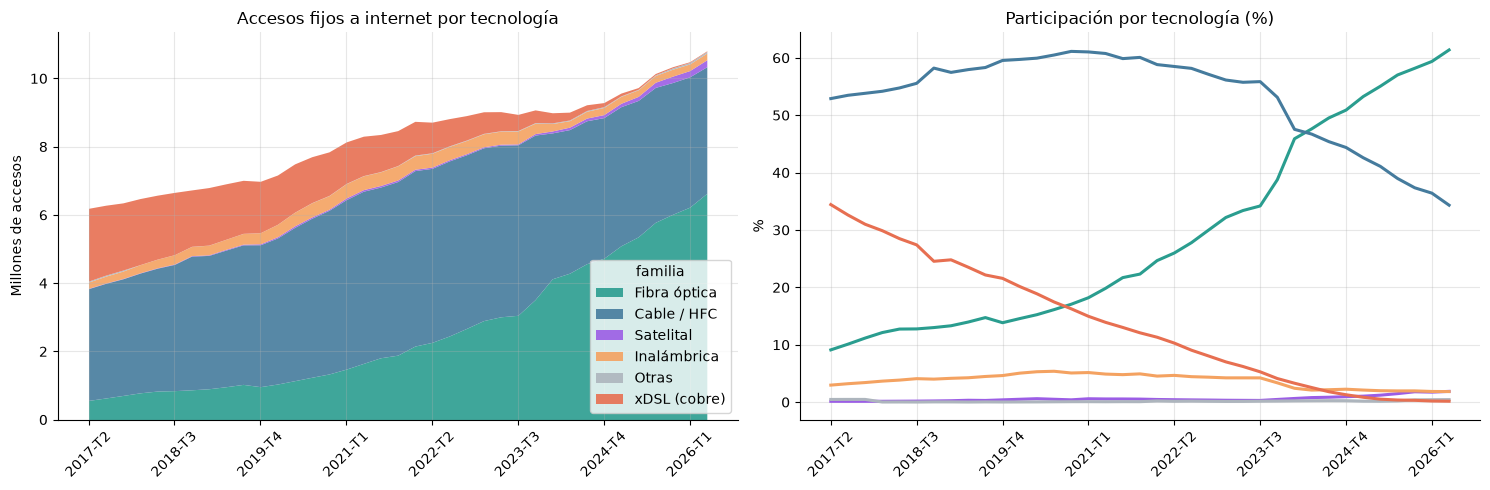

In [26]:
# 8.1 Evolución de los accesos por familia tecnológica: la fibra reemplaza al cobre
orden = familias.iloc[-1].sort_values(ascending=False).index
colores = {"Fibra óptica": "#2a9d8f", "Cable / HFC": "#457b9d", "xDSL (cobre)": "#e76f51",
           "Inalámbrica": "#f4a261", "Satelital": "#9b5de5", "Otras": "#adb5bd"}

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
(familias[orden] / 1e6).plot.area(ax=ax[0], color=[colores[c] for c in orden], alpha=0.9, linewidth=0)
ax[0].set_title("Accesos fijos a internet por tecnología")
ax[0].set_ylabel("Millones de accesos"); ax[0].set_xlabel("")
familias_pct[orden].plot(ax=ax[1], color=[colores[c] for c in orden], linewidth=2.2)
ax[1].set_title("Participación por tecnología (%)"); ax[1].set_ylabel("%"); ax[1].set_xlabel("")
for a_ in ax:
    a_.tick_params(axis="x", rotation=45)
ax[1].get_legend().remove()
plt.tight_layout(); plt.show()

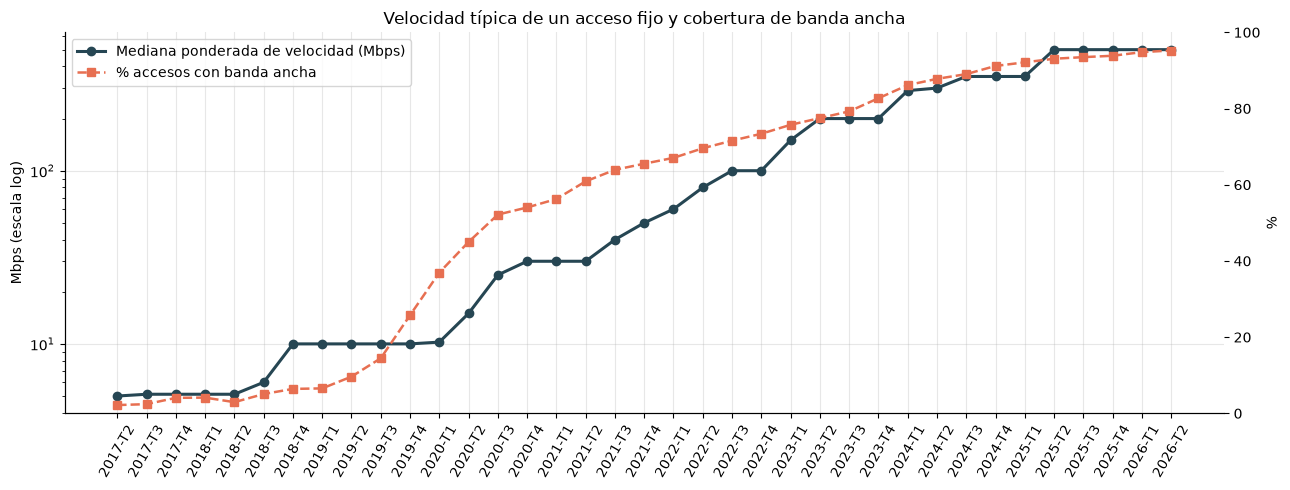

In [27]:
# 8.1b El salto de velocidad: mediana ponderada y porcentaje de accesos con banda ancha (≥25/5 Mbps)
pct_banda = 100 * banda[True] / banda.sum(axis=1)
fig, ax1 = plt.subplots(figsize=(13, 5))
ax1.plot(resumen_periodo.index, resumen_periodo["vel_mediana_ponderada"], "o-", color="#264653", lw=2.2,
         label="Mediana ponderada de velocidad (Mbps)")
ax1.set_yscale("log"); ax1.set_ylabel("Mbps (escala log)")
ax2 = ax1.twinx()
ax2.plot(pct_banda.index, pct_banda.values, "s--", color="#e76f51", lw=1.8, label="% accesos con banda ancha")
ax2.set_ylim(0, 100); ax2.set_ylabel("%"); ax2.grid(False)
ax1.set_title("Velocidad típica de un acceso fijo y cobertura de banda ancha")
ax1.tick_params(axis="x", rotation=60)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left")
plt.tight_layout(); plt.show()

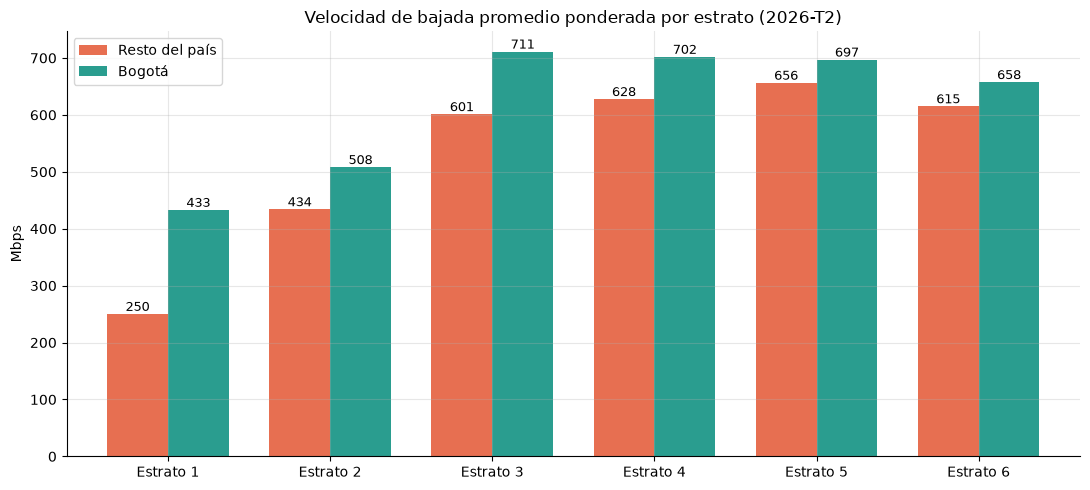

In [28]:
# 8.2 Velocidad promedio ponderada por estrato: Bogotá vs. resto del país (último periodo)
vel_estrato = (df_enr[(df_enr["periodo"] == ULTIMO) & df_enr["estrato"].notnull()]
               .groupby(["estrato", "es_bogota"])[["acc_x_vel", "acc_con_vel"]].sum().compute())
vel_estrato = (vel_estrato["acc_x_vel"] / vel_estrato["acc_con_vel"]).unstack().sort_index()
vel_estrato.columns = ["Resto del país", "Bogotá"]
vel_estrato.index = [f"Estrato {int(e)}" for e in vel_estrato.index]

ax = vel_estrato.plot.bar(color=["#e76f51", "#2a9d8f"], rot=0, width=0.75)
ax.set_title(f"Velocidad de bajada promedio ponderada por estrato ({ULTIMO})")
ax.set_ylabel("Mbps")
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.0f", fontsize=9)
plt.tight_layout(); plt.show()

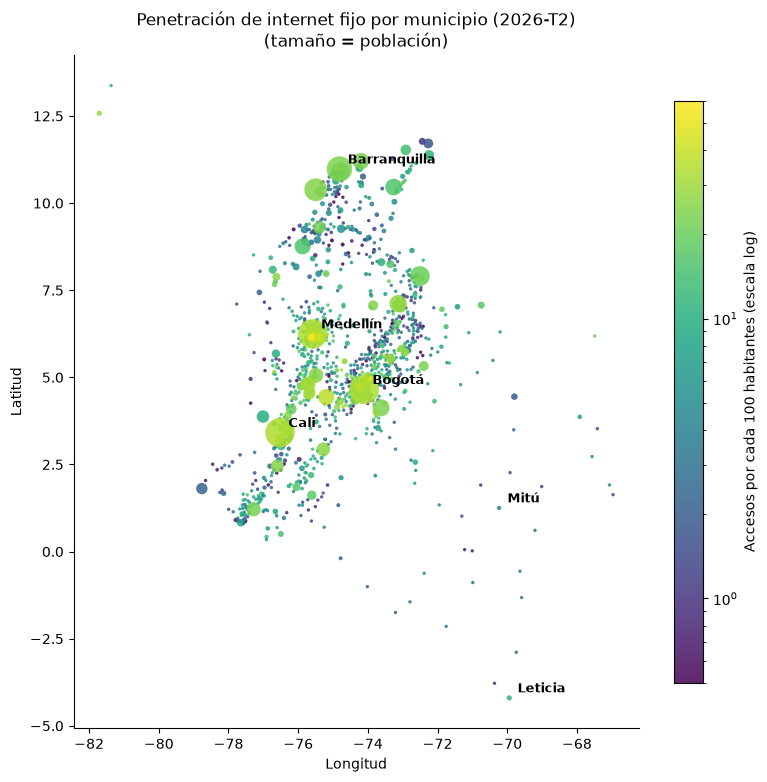

In [29]:
# 8.3 Mapa de penetración municipal (gracias al join con DIVIPOLA)
from matplotlib.colors import LogNorm

m = mun_ult.dropna(subset=["latitud"]).sort_values("penetracion")
fig, ax = plt.subplots(figsize=(8, 10))
sc = ax.scatter(m["longitud"], m["latitud"], c=m["penetracion"].clip(0.1, 60), cmap="viridis",
                norm=LogNorm(vmin=0.5, vmax=60), s=np.clip(m["poblacion"] / 4_000, 6, 450),
                alpha=0.85, edgecolor="none")
for cod, nombre in [("11001", "Bogotá"), ("05001", "Medellín"), ("76001", "Cali"),
                    ("08001", "Barranquilla"), ("91001", "Leticia"), ("97001", "Mitú")]:
    f = m[m["cod_municipio"] == cod]
    if len(f):
        ax.annotate(nombre, (f["longitud"].iloc[0], f["latitud"].iloc[0]), xytext=(6, 4),
                    textcoords="offset points", fontsize=9, fontweight="bold")
plt.colorbar(sc, ax=ax, shrink=0.6, label="Accesos por cada 100 habitantes (escala log)")
ax.set_title(f"Penetración de internet fijo por municipio ({PER_POB})\n(tamaño = población)")
ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud"); ax.set_aspect("equal"); ax.grid(False)
plt.tight_layout(); plt.show()

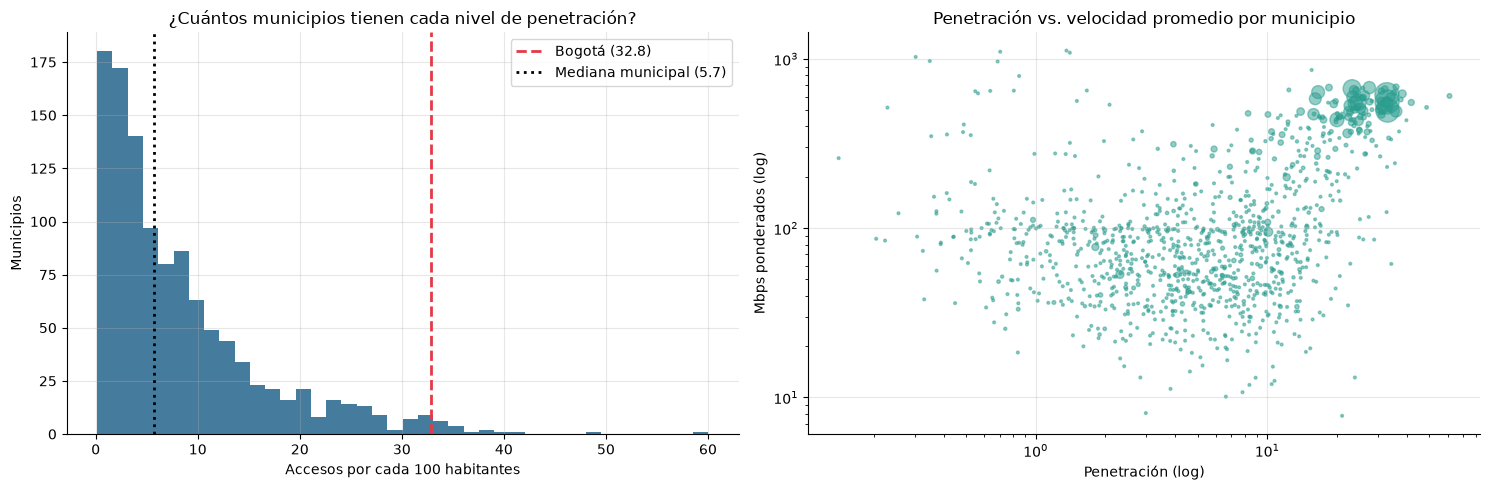

In [30]:
# 8.4 Distribución de la penetración municipal y relación con la velocidad
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].hist(mun_ult["penetracion"].clip(upper=60), bins=40, color="#457b9d")
ax[0].axvline(bog["penetracion"], color="#e63946", ls="--", lw=2, label=f"Bogotá ({bog['penetracion']:.1f})")
ax[0].axvline(mun_ult["penetracion"].median(), color="k", ls=":", lw=2,
              label=f"Mediana municipal ({mun_ult['penetracion'].median():.1f})")
ax[0].set_title("¿Cuántos municipios tienen cada nivel de penetración?")
ax[0].set_xlabel("Accesos por cada 100 habitantes"); ax[0].set_ylabel("Municipios"); ax[0].legend()

ax[1].scatter(mun_ult["penetracion"], mun_ult["vel_ponderada"], s=np.clip(mun_ult["poblacion"] / 8_000, 4, 300),
              alpha=0.5, color="#2a9d8f")
ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_title("Penetración vs. velocidad promedio por municipio")
ax[1].set_xlabel("Penetración (log)"); ax[1].set_ylabel("Mbps ponderados (log)")
plt.tight_layout(); plt.show()

# 9. Paralelización con todos los modos de Dask

Se ejecuta **la misma consulta** (leer los CSV, limpiar, enriquecer y agregar accesos y velocidad por periodo y familia) con cada forma de ejecución, midiendo el tiempo de punta a punta. Luego se muestran las demás interfaces de Dask.

| Modo | Qué es | Cuándo conviene |
|---|---|---|
| `synchronous` | Un solo hilo, sin paralelismo | Depurar (permite `pdb`, trazas claras); línea base |
| `threads` | Pool de hilos en un proceso (por defecto en DataFrame/Array) | Código que libera el GIL: pandas/numpy, I/O |
| `processes` | Pool de procesos (por defecto en Bag) | Código Python puro que sostiene el GIL |
| `distributed` | `Client` + `LocalCluster` (o un clúster real): workers, dashboard, memoria distribuida | Producción, varias máquinas, *futures*, `persist` en el clúster |
| `dask.delayed` | Paralelizar funciones Python arbitrarias como un grafo | Pipelines a la medida |
| *Futures* (`submit`, `map`, `scatter`, `as_completed`) | Ejecución inmediata y asíncrona | Tareas dinámicas, resultados a medida que llegan |
| `dask.bag` | Colecciones de objetos Python (JSON, texto) | Datos semiestructurados, map/filter/fold |
| `dask.array` | Arreglos NumPy por bloques (chunks) | Cálculo numérico |

In [31]:
def consulta_completa(base):
    # Mismo plan en todos los modos: CSV -> limpieza -> map_partitions -> groupby/agg
    return (base.map_partitions(enriquecer)
                .groupby(["periodo", "familia"])
                .agg(accesos=("no_de_accesos", "sum"), acc_x_vel=("acc_x_vel", "sum"),
                     acc_con_vel=("acc_con_vel", "sum")))


resultados = []


def medir(modo, funcion, **extra):
    t0 = time.perf_counter()
    salida = funcion()
    seg = time.perf_counter() - t0
    resultados.append({"modo": modo, "segundos": seg, **extra})
    print(f"{modo:<38s} {seg:8.2f} s")
    return salida


referencia = consulta_completa(df_lazy).compute(scheduler="threads")  # resultado contra el cual validar
print(f"La consulta produce {len(referencia)} grupos (periodo × familia)\n")

La consulta produce 222 grupos (periodo × familia)



## 9.1 Schedulers de una sola máquina: `synchronous`, `threads`, `processes`

Se elige con `compute(scheduler=...)` o con `dask.config.set(scheduler=...)` como contexto.

In [32]:
r_sync = medir("synchronous (1 hilo)", lambda: consulta_completa(df_lazy).compute(scheduler="synchronous"))

with dask.config.set(scheduler="threads", num_workers=NUCLEOS):
    r_thr = medir(f"threads ({NUCLEOS} hilos)", lambda: consulta_completa(df_lazy).compute())

r_proc = medir(f"processes ({NUCLEOS} procesos)",
               lambda: consulta_completa(df_lazy).compute(scheduler="processes", num_workers=NUCLEOS))

# El resultado es el mismo sin importar el scheduler
for r in (r_sync, r_thr, r_proc):
    pd.testing.assert_frame_equal(r.sort_index(), referencia.sort_index())
print("\n✔ Los tres schedulers producen exactamente el mismo resultado")

synchronous (1 hilo)                      10.64 s


threads (8 hilos)                          9.01 s


processes (8 procesos)                    88.04 s

✔ Los tres schedulers producen exactamente el mismo resultado


## 9.2 Scheduler distribuido: `Client` + `LocalCluster`

Al crear un `Client`, este se vuelve el scheduler por defecto. El `LocalCluster` lanza *workers* (procesos) con sus propios hilos y memoria; el mismo código funcionaría en un clúster real cambiando solo la dirección del scheduler. Con `persist()` los datos quedan **en la memoria de los workers** y las consultas siguientes no vuelven a leer los CSV.

In [33]:
cluster = LocalCluster(n_workers=NUCLEOS, threads_per_worker=1, processes=True, dashboard_address=":0")
client = Client(cluster)
print(client)
print("Dashboard:", client.dashboard_link)

<Client: 'tcp://127.0.0.1:50821' processes=8 threads=8, memory=8.00 GiB>
Dashboard: http://127.0.0.1:50820/status


In [34]:
r_dist = medir(f"distributed ({NUCLEOS} workers × 1 hilo)", lambda: consulta_completa(df_lazy).compute())
pd.testing.assert_frame_equal(r_dist.sort_index(), referencia.sort_index())

# persist en el clúster: se lee y limpia una sola vez, las particiones quedan en los workers
t0 = time.perf_counter()
df_cluster = client.persist(df_lazy)
distributed.wait(df_cluster)
print(f"persist en el clúster: {time.perf_counter() - t0:,.2f} s")
r_pers = medir("distributed + datos persistidos", lambda: consulta_completa(df_cluster).compute())
pd.testing.assert_frame_equal(r_pers.sort_index(), referencia.sort_index())

distributed (8 workers × 1 hilo)           4.45 s


persist en el clúster: 2.79 s


distributed + datos persistidos            1.68 s


## 9.3 `dask.delayed`: un pipeline propio

En lugar de usar Dask DataFrame, se arma a mano el grafo: por cada archivo `leer → limpiar → resumir` y al final un `combinar`. Dask ejecuta en paralelo todas las ramas independientes. Se calcula la velocidad ponderada por departamento en el último periodo, leyendo directamente los CSV del dataset reciente.

In [35]:
@dask.delayed
def leer(ruta):
    return pd.read_csv(ruta, dtype=str, usecols=["anno", "trimestre", "departamento",
                                                 "velocidad_bajada", "accesos_fijos_internet"])


@dask.delayed
def limpiar(pdf):
    pdf = pdf[(pdf["anno"] == str(ULT_ANNO)) & (pdf["trimestre"] == str(ULT_TRIM))].copy()
    pdf["vel"] = pdf["velocidad_bajada"].str.replace(",", ".", regex=False).astype(float)
    pdf["acc"] = pdf["accesos_fijos_internet"].astype("int64")
    valida = pdf["vel"] <= VEL_MAX
    pdf["acc_con_vel"] = pdf["acc"].where(valida, 0)
    pdf["acc_x_vel"] = (pdf["vel"] * pdf["acc"]).where(valida, 0)
    return pdf


@dask.delayed
def resumir(pdf):
    return pdf.groupby("departamento")[["acc", "acc_con_vel", "acc_x_vel"]].sum()


@dask.delayed
def combinar(parciales):
    total = pd.concat(parciales).groupby(level=0).sum()
    total["vel_ponderada"] = total["acc_x_vel"] / total["acc_con_vel"]
    return total.sort_values("vel_ponderada", ascending=False)


archivos = sorted(glob.glob(f"{DATOS}/accesos_recientes/parte_*.csv"))
grafo = combinar([resumir(limpiar(leer(r))) for r in archivos])
print(f"Tareas en el grafo: {len(grafo.dask)}")
try:
    display(grafo.visualize(rankdir="LR"))       # dibuja el grafo (requiere graphviz)
except Exception as e:
    print("No se pudo dibujar el grafo:", e)

Tareas en el grafo: 28
No se pudo dibujar el grafo: failed to execute PosixPath('dot'), make sure the Graphviz executables are on your systems' PATH


In [36]:
vel_dep = medir("dask.delayed (pipeline propio, distributed)", lambda: grafo.compute())
vel_dep[["acc", "vel_ponderada"]].head(10).style.format({"acc": "{:,.0f}", "vel_ponderada": "{:,.1f} Mbps"})

dask.delayed (pipeline propio, distributed)     0.34 s


,acc,vel_ponderada
departamento,,
BOGOTÁ D.C.,"2,604,868",615.0 Mbps
ATLÁNTICO,"490,799",612.1 Mbps
SANTANDER,"471,653",564.3 Mbps
CUNDINAMARCA,"818,550",512.7 Mbps
QUINDÍO,"146,920",507.6 Mbps
ANTIOQUIA,"1,863,160",507.0 Mbps
RISARALDA,"255,608",494.5 Mbps
BOLÍVAR,"336,832",490.3 Mbps
"ARCHIPIÉLAGO DE SAN ANDRÉS, PROVIDENCIA Y SANTA CATALINA","16,516",485.0 Mbps


## 9.4 Futures: `submit`, `map`, `scatter`, `as_completed`

Los *futures* se ejecutan **apenas se envían** (no son perezosos). Se usa `scatter` para mandar una vez la tabla del último periodo a los workers, `client.map` para calcular indicadores de cada departamento en paralelo y `as_completed` para procesar los resultados en el orden en que terminan.

In [37]:
ultimo_pd = df_enr[df_enr["periodo"] == ULTIMO][
    ["departamento", "municipio", "familia", "banda_ancha", "velocidad_bajada", "no_de_accesos", "acc_x_vel", "acc_con_vel"]].compute()
datos_fut = client.scatter(ultimo_pd, broadcast=True)   # se envía una sola vez a todos los workers


def indicadores_departamento(depto, datos):
    g = datos[datos["departamento"] == depto]
    acc = g["no_de_accesos"].sum()
    return {"departamento": depto,
            "accesos": int(acc),
            "municipios": g["municipio"].nunique(),
            "vel_ponderada": g["acc_x_vel"].sum() / g["acc_con_vel"].sum(),
            "%_fibra": 100 * g.loc[g["familia"] == "Fibra óptica", "no_de_accesos"].sum() / acc,
            "%_banda_ancha": 100 * g.loc[g["banda_ancha"], "no_de_accesos"].sum() / acc}


def tarea_futures():
    deptos = sorted(ultimo_pd["departamento"].unique())
    futuros = client.map(indicadores_departamento, deptos, datos=datos_fut)   # uno por departamento
    filas = []
    for fut in as_completed(futuros):        # llegan en orden de finalización, no de envío
        filas.append(fut.result())
    return pd.DataFrame(filas).set_index("departamento").sort_values("%_fibra")


ind_dep = medir("futures (client.map + as_completed)", tarea_futures)

# submit: una sola tarea que depende de futures anteriores (Dask resuelve la dependencia)
f_total = client.submit(lambda d: int(d["no_de_accesos"].sum()), datos_fut)
print(f"Total de accesos calculado con client.submit: {f_total.result():,}")
ind_dep.round(1).head(10)

futures (client.map + as_completed)        0.12 s
Total de accesos calculado con client.submit: 10,810,248


,accesos,municipios,vel_ponderada,%_fibra,%_banda_ancha
departamento,,,,,
VAUPÉS,1625,6,97.40,1.10,98.00
GUAINÍA,3096,8,96.00,4.70,95.40
VICHADA,7047,4,94.70,6.50,92.30
CALDAS,204565,27,399.70,41.90,91.20
RISARALDA,255608,14,494.50,42.60,95.20
SUCRE,106193,26,284.00,43.40,91.40
ANTIOQUIA,1863160,125,507.00,44.70,95.40
QUINDÍO,146920,12,507.60,48.30,97.20
CÓRDOBA,143012,30,328.50,53.80,87.00


## 9.5 `dask.bag`: procesamiento de texto crudo

Bag trabaja con objetos Python, ideal para datos semiestructurados. Aquí se leen los CSV del dataset reciente **como líneas de texto**, se parsean a diccionarios, se filtra el último periodo y se usa `foldby` (un *reduce por llave*) para obtener el ranking de proveedores.

In [38]:
COLUMNAS = COLUMNAS_RECIENTE          # nombres originales: incluye "accesos_fijos_internet"


def parsear(linea):
    return dict(zip(COLUMNAS, next(csv.reader([linea]))))


def tarea_bag():
    lineas = db.read_text(f"{DATOS}/accesos_recientes/parte_*.csv", blocksize=None)
    registros = (lineas.filter(lambda l: not l.startswith('"anno"'))          # quita encabezados
                       .map(parsear)
                       .filter(lambda r: r["anno"] == str(ULT_ANNO) and r["trimestre"] == str(ULT_TRIM)))
    return (registros.foldby(key="proveedor",
                             binop=lambda acum, r: acum + int(r["accesos_fijos_internet"]), initial=0,
                             combine=operator.add, combine_initial=0)
                     .topk(10, key=1)
                     .compute())


top_prov = medir("dask.bag (texto -> dicts -> foldby)", tarea_bag)
top_prov = pd.DataFrame(top_prov, columns=["proveedor", "accesos"]).set_index("proveedor")
top_prov["%"] = 100 * top_prov["accesos"] / acc_ult
top_prov

dask.bag (texto -> dicts -> foldby)        1.40 s


,accesos,%
proveedor,,
COMUNICACION CELULAR S A COMCEL S A,3648798,33.75
UNE EPM TELECOMUNICACIONES S.A.,1819246,16.83
COLOMBIA TELECOMUNICACIONES S.A E.S.P BIC,1532994,14.18
EMPRESA DE TELECOMUNICACIONES DE BOGOTA S.A. ESP,617812,5.72
EMPRESAS MUNICIPALES DE CALI EICE E.S.P,258839,2.39
STARLINK COLOMBIA SAS,189647,1.75
Celsia Internet S.A.S.,150701,1.39
H V TELEVISION S.A.S.,135689,1.26
SOMOS NETWORKS COLOMBIA S.A.S. BIC,97225,0.90


## 9.6 `dask.array`: cálculo numérico por bloques

Las columnas numéricas se convierten en arreglos Dask (`to_dask_array(lengths=True)` calcula el tamaño de cada bloque). Con ellos se calcula la media ponderada, la desviación estándar ponderada y un **histograma ponderado** de velocidades en escala logarítmica, todo por bloques en paralelo.

dask.array (histograma ponderado)          0.42 s
Bloques del arreglo: 21 | media ponderada 501.0 Mbps | desv. 358.5 Mbps


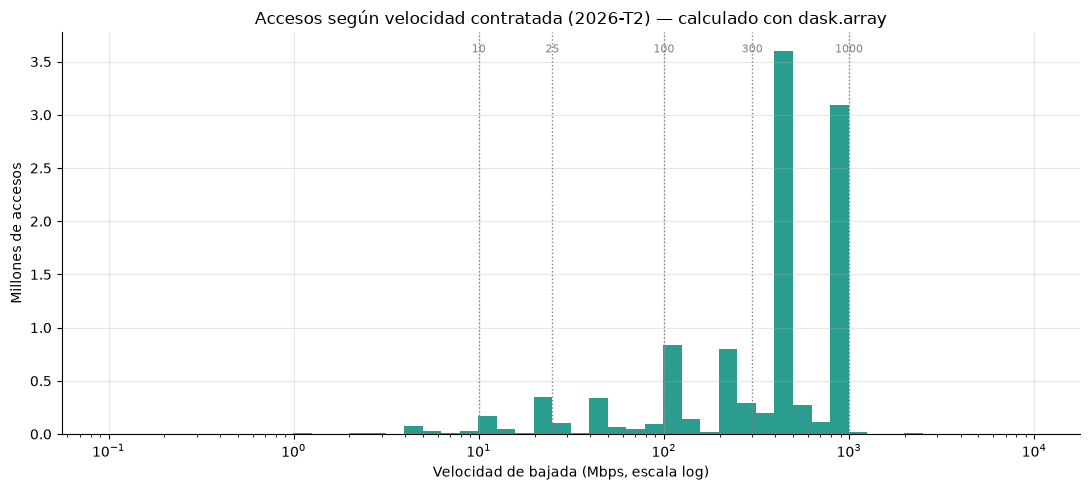

In [39]:
def tarea_array():
    ult = df_cluster[(df_cluster["periodo"] == ULTIMO) & df_cluster["velocidad_bajada"].notnull()]
    vel = ult["velocidad_bajada"].to_dask_array(lengths=True)
    acc = ult["no_de_accesos"].to_dask_array(lengths=True).astype("float64")
    media = (vel * acc).sum() / acc.sum()
    desv = da.sqrt((acc * (vel - media) ** 2).sum() / acc.sum())
    hist, bordes = da.histogram(da.log10(da.clip(vel, 0.1, None)), bins=50, range=(-1, 4), weights=acc)
    return dask.compute(media, desv, hist, bordes, vel.chunks)


media_a, desv_a, hist_a, bordes_a, chunks_a = medir("dask.array (histograma ponderado)", tarea_array)
print(f"Bloques del arreglo: {len(chunks_a[0])} | media ponderada {media_a:,.1f} Mbps | desv. {desv_a:,.1f} Mbps")

centros = 10 ** ((bordes_a[:-1] + bordes_a[1:]) / 2)
fig, ax = plt.subplots()
ax.bar(centros, hist_a / 1e6, width=np.diff(10 ** bordes_a), color="#2a9d8f", align="center")
ax.set_xscale("log")
for v in (10, 25, 100, 300, 1000):
    ax.axvline(v, color="gray", ls=":", lw=1)
    ax.text(v, ax.get_ylim()[1] * 0.95, f"{v}", ha="center", fontsize=8, color="gray")
ax.set_title(f"Accesos según velocidad contratada ({ULTIMO}) — calculado con dask.array")
ax.set_xlabel("Velocidad de bajada (Mbps, escala log)"); ax.set_ylabel("Millones de accesos")
plt.tight_layout(); plt.show()

## 9.7 Escalamiento: número de workers y particiones

Se repite la consulta en clústeres de 1 a N workers para medir el *speedup* $S = T_1 / T_N$, y luego se varía el número de particiones con `repartition` para ver el efecto de la granularidad (pocas particiones = poco paralelismo; demasiadas = sobrecarga del scheduler).

In [40]:
client.close(); cluster.close()        # se libera el clúster principal

escalamiento = []
for n in sorted({1, 2, NUCLEOS}):
    with LocalCluster(n_workers=n, threads_per_worker=1, dashboard_address=":0") as c, Client(c):
        t0 = time.perf_counter()
        consulta_completa(df_lazy).compute()
        escalamiento.append({"workers": n, "segundos": time.perf_counter() - t0})
escalamiento = pd.DataFrame(escalamiento).set_index("workers")
escalamiento["speedup"] = escalamiento["segundos"].iloc[0] / escalamiento["segundos"]
escalamiento["eficiencia_%"] = 100 * escalamiento["speedup"] / escalamiento.index
escalamiento

,segundos,speedup,eficiencia_%
workers,,,
1,12.80,1.00,100.00
2,7.43,1.72,86.14
8,6.45,1.98,24.80


In [41]:
# Granularidad: mismas filas (ya en memoria) repartidas en distinto número de particiones
granularidad = []
for p in [1, 2, 4, 12, 48, 192]:
    dp = df.repartition(npartitions=p).persist()
    t0 = time.perf_counter()
    consulta_completa(dp).compute(scheduler="threads")
    granularidad.append({"particiones": p, "segundos": time.perf_counter() - t0})
    del dp
granularidad = pd.DataFrame(granularidad).set_index("particiones")
granularidad

,segundos
particiones,
1,5.04
2,4.27
4,4.56
12,4.45
48,4.60
192,5.70


## 9.8 Resumen de tiempos

,modo,segundos,speedup_vs_sync
0,synchronous (1 hilo),10.64,1.00x
1,threads (8 hilos),9.01,1.18x
2,processes (8 procesos),88.04,0.12x
3,distributed (8 workers × 1 hilo),4.45,2.39x
4,distributed + datos persistidos,1.68,6.34x
5,"dask.delayed (pipeline propio, distributed)",0.34,31.60x


Otras interfaces (consultas distintas, solo referencia de tiempo):


,modo,segundos
6,futures (client.map + as_completed),0.12
7,dask.bag (texto -> dicts -> foldby),1.40
8,dask.array (histograma ponderado),0.42


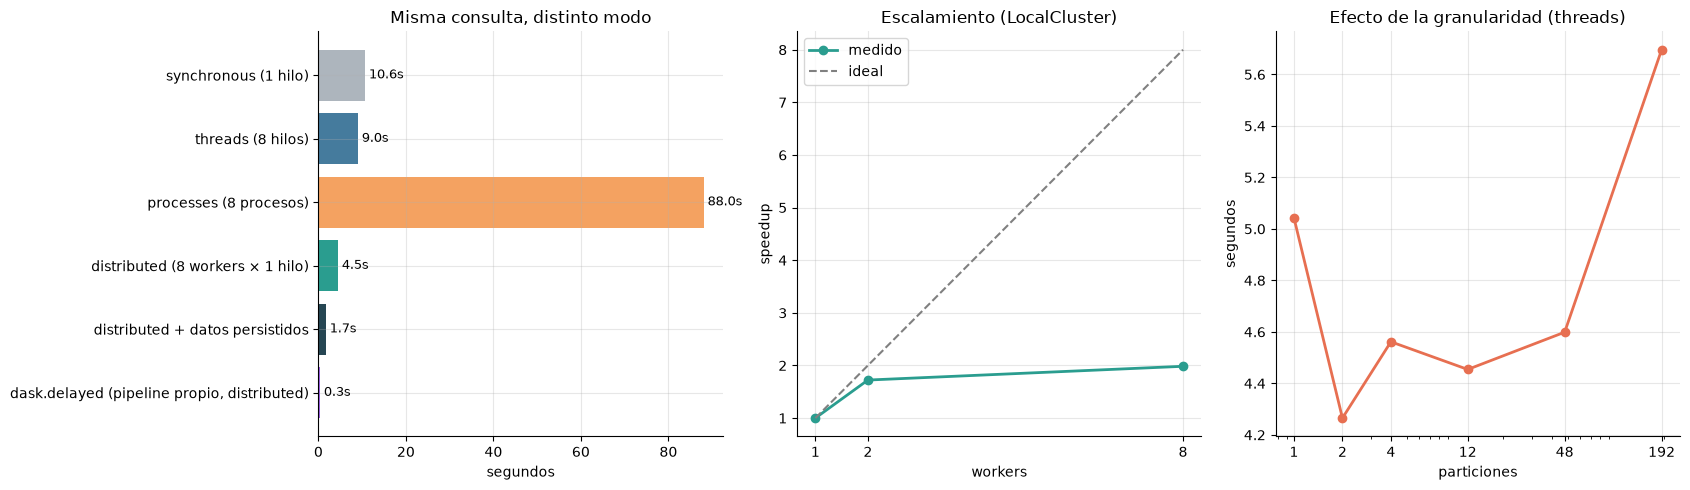

In [42]:
tabla = pd.DataFrame(resultados)
base = tabla.loc[tabla["modo"].str.startswith("synchronous"), "segundos"].iloc[0]
comparables = tabla.iloc[:6].copy()      # los seis modos que ejecutan exactamente la misma consulta
comparables["speedup_vs_sync"] = base / comparables["segundos"]
display(comparables.style.format({"segundos": "{:.2f}", "speedup_vs_sync": "{:.2f}x"}))
print("Otras interfaces (consultas distintas, solo referencia de tiempo):")
display(tabla.iloc[6:].style.format({"segundos": "{:.2f}"}))

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
cols = ["#adb5bd", "#457b9d", "#f4a261", "#2a9d8f", "#264653", "#9b5de5"]
ax[0].barh(comparables["modo"], comparables["segundos"], color=cols[:len(comparables)])
ax[0].invert_yaxis(); ax[0].set_xlabel("segundos"); ax[0].set_title("Misma consulta, distinto modo")
for i, v in enumerate(comparables["segundos"]):
    ax[0].text(v, i, f" {v:.1f}s", va="center", fontsize=9)
ax[1].plot(escalamiento.index, escalamiento["speedup"], "o-", lw=2, label="medido", color="#2a9d8f")
ax[1].plot(escalamiento.index, escalamiento.index, "--", color="gray", label="ideal")
ax[1].set_xlabel("workers"); ax[1].set_ylabel("speedup"); ax[1].set_title("Escalamiento (LocalCluster)")
ax[1].set_xticks(escalamiento.index); ax[1].legend()
ax[2].plot(granularidad.index, granularidad["segundos"], "o-", lw=2, color="#e76f51")
ax[2].set_xscale("log"); ax[2].set_xticks(granularidad.index); ax[2].set_xticklabels(granularidad.index)
ax[2].set_xlabel("particiones"); ax[2].set_ylabel("segundos"); ax[2].set_title("Efecto de la granularidad (threads)")
plt.tight_layout(); plt.show()

# 10. Conclusiones

**Sobre los datos (brecha digital):**

- La fibra óptica pasó de ser minoritaria a ser la tecnología dominante en pocos años, desplazando al cobre (xDSL) y al cable/HFC (gráfica 8.1). Con ello, la proporción de accesos que cumple la definición de banda ancha de la CRC (≥25/5 Mbps) creció de forma sostenida.
- La brecha territorial sigue siendo grande: Bogotá tiene varias veces la penetración de la mediana municipal, y cientos de municipios están por debajo de 5 accesos por cada 100 habitantes (mapa 8.3 y el histograma 8.4). En la periferia (Amazonía, Orinoquía, Pacífico) el acceso depende de soluciones satelitales e inalámbricas de baja velocidad (filtro 5.5).
- Dentro de cada estrato, Bogotá tiene velocidades promedio mayores que el resto del país (gráfica 8.2): la brecha no es solo socioeconómica, también es territorial.
- El join con el dataset de población permitió **validar** la agregación hecha con Dask: los accesos sumados desde los registros crudos coinciden con la cifra de MinTIC por municipio.

**Sobre Dask:**

- Dask DataFrame permitió trabajar con ~2,8 M de registros con la misma API de pandas, sin cargar el CSV completo en un solo proceso. La evaluación perezosa y `dask.compute(...)` con varias salidas evitan lecturas repetidas.
- `map_partitions` con código vectorizado fue mucho más rápido que `apply(axis=1)` para la misma regla: el apply por filas solo se justifica con lógica que no se puede vectorizar.
- Para esta carga (pandas, que libera el GIL en buena parte), `threads` y `distributed` dan el mejor tiempo; `processes` paga el costo de serializar particiones entre procesos, y `synchronous` es la línea base sin paralelismo. Persistir los datos en el clúster elimina la lectura del CSV y reduce el tiempo de las consultas siguientes de forma notable.
- El *speedup* con más workers está limitado por los núcleos disponibles (en Colab normalmente 2) y por la parte de I/O, y la granularidad importa: con una partición no hay paralelismo y con demasiadas particiones la sobrecarga del scheduler domina.
- Cada interfaz tiene su lugar: `delayed` para pipelines propios, *futures* para tareas dinámicas y resultados incrementales, `bag` para texto/JSON y `array` para cálculo numérico por bloques.

# Referencias

- MinTIC. *Internet Fijo Accesos por tecnología y segmento*. Datos Abiertos Colombia. https://www.datos.gov.co/d/n48w-gutb
- MinTIC. *Accesos Fijos a Internet por Departamento, Municipio y población*. https://www.datos.gov.co/d/tvzi-ba2g
- DANE. *DIVIPOLA - Códigos municipios*. https://www.datos.gov.co/d/gdxc-w37w
- Dask Development Team. *Dask: Library for dynamic task scheduling*. https://docs.dask.org
- Rocklin, M. (2015). *Dask: Parallel Computation with Blocked algorithms and Task Scheduling*. Proceedings of the 14th Python in Science Conference.